# Spotify Track Analysis — Exploratory Data Analysis

## 1. Purpose and questions

This notebook explores a Spotify tracks dataset (114,000 rows in the raw file) to describe how a track's **popularity** — a 0–100 score defined by Spotify — is *associated* with its audio features, its genre and whether it is flagged explicit. The analysis is descriptive: it reports associations and does not test causes.

**Questions**

1. Is the data clean enough to analyse, and what did cleaning change?
2. How are audio features (danceability, energy, loudness, …) associated with popularity?
3. How does popularity differ between genres?
4. Do explicit tracks differ in popularity from clean tracks?
5. What can this dataset *not* tell us?

**Notebook flow:** purpose → setup → dataset → data quality and cleaning → exploratory analysis (5.1–5.11) → findings → limitations → conclusion.

**How to run:** install the dependencies with `pip install -r requirements.txt`, then run all cells from the repository root or from `notebooks/`. By default the notebook also writes its charts to `visuals/` and the dashboard to `dashboard/` (set `SAVE_OUTPUTS = False` in the setup cell to turn this off).

## 2. Setup

Imports, plotting style, file locations and two small helpers. The repository root is found by looking for `data/spotify.csv`, so the notebook works whether it is started from the repository root or from `notebooks/`. Colours are defined once and reused so the same meaning always has the same colour.

In [1]:
%matplotlib inline
import os
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# ── Behaviour switches ──
SAVE_OUTPUTS = True      # True: also write charts to visuals/ and the dashboard to dashboard/ (as before)
RANDOM_SEED = 42         # used for the 5,000-track plotting sample

# ── Colours (one meaning, one colour) ──
GREEN, BLUE, RED, TEAL, ORANGE = "#1DB954", "#2E86AB", "#E63946", "#2EC4B6", "#FF9F1C"

# ── Plot style ──
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.dpi": 100,
    "font.family": "sans-serif",
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_columns", 30)

# ── Paths: search upward from the working directory for data/spotify.csv ──
ROOT = next((p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
             if (p / "data" / "spotify.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("data/spotify.csv not found. Start Jupyter from inside the repository.")
DATA_PATH = ROOT / "data" / "spotify.csv"
VISUALS_DIR = ROOT / "visuals"
DASHBOARD_DIR = ROOT / "dashboard"
if SAVE_OUTPUTS:
    os.makedirs(VISUALS_DIR, exist_ok=True)
    os.makedirs(DASHBOARD_DIR, exist_ok=True)

# ── Labels with units, reused by several charts ──
FEATURE_LABELS = {
    "danceability": "Danceability (0–1)", "energy": "Energy (0–1)", "speechiness": "Speechiness (0–1)",
    "acousticness": "Acousticness (0–1)", "instrumentalness": "Instrumentalness (0–1)",
    "liveness": "Liveness (0–1)", "valence": "Valence (0–1)", "tempo": "Tempo (BPM)",
    "loudness": "Loudness (dB)",
}


def finish_figure(fig, filename):
    """Show a figure inline and, if SAVE_OUTPUTS is on, save it to visuals/ at 300 DPI."""
    if SAVE_OUTPUTS:
        fig.savefig(VISUALS_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    if SAVE_OUTPUTS:
        print(f"Saved: visuals/{filename}")


def color_boxes(ax, colors):
    """Give each box of a seaborn box plot its own colour (works with seaborn 0.12 and 0.13+)."""
    for box, color in zip(ax.patches, colors):
        box.set_facecolor(color)


def label_bar_ends(ax, texts):
    """Write one text label just past the end of each horizontal bar."""
    x_max = ax.get_xlim()[1]
    for bar, text in zip(ax.patches, texts):
        ax.text(bar.get_width() + x_max * 0.01, bar.get_y() + bar.get_height() / 2, text,
                va="center", fontsize=9)


print("Data file:", DATA_PATH.relative_to(ROOT))

Data file: data/spotify.csv


## 3. Dataset

`data/spotify.csv` has one row per track-and-genre listing. Column groups (audio-feature meanings follow Spotify's published audio-feature definitions):

| Group | Columns |
|---|---|
| Identifiers and names | `track_id`, `artists`, `album_name`, `track_name` |
| Target | `popularity` — Spotify's 0–100 score (the calculation is not part of the dataset) |
| Audio features | `danceability`, `energy`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence` (all 0–1), `loudness` (dB), `tempo` (BPM), `key`, `mode`, `time_signature`, `duration_ms` |
| Other | `explicit` (True/False), `track_genre` |
| Artefact | `Unnamed: 0` — an exported row index with no analytical value |

The dataset has **no release-date column**, so nothing here can be analysed over time.

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print(f"Raw data: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns\n")

schema = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_values": df_raw.isna().sum(),
    "unique_values": df_raw.nunique(),
})
schema

Raw data: 114,000 rows × 21 columns



,dtype,missing_values,unique_values
Unnamed: 0,int64,0,114000
track_id,str,0,89741
artists,str,1,31437
album_name,str,1,46589
track_name,str,1,73608
popularity,int64,0,101
duration_ms,int64,0,50697
explicit,bool,0,2
danceability,float64,0,1174
energy,float64,0,2083


## 4. Data quality and cleaning

**Checks first, then cleaning.** The cleaning rules are the same ones used in `build_eda_assets.py` and described in the data cleaning report:

1. Drop the exported index column `Unnamed: 0`.
2. Drop rows missing `artists`, `album_name` or `track_name`.
3. Drop repeated `track_id`s, keeping the **first** occurrence.
4. Add `duration_min` (`duration_ms` ÷ 60,000).

The cell below only *measures* the raw data; nothing is changed yet.

In [3]:
ESSENTIAL_TEXT_COLUMNS = ["artists", "album_name", "track_name"]

rows_missing_text = df_raw[ESSENTIAL_TEXT_COLUMNS].isna().any(axis=1).sum()
repeated_track_rows = df_raw.duplicated("track_id").sum()
genres_per_track = df_raw.groupby("track_id")["track_genre"].nunique()
raw_genre_sizes = df_raw["track_genre"].value_counts()

print("Missing values")
print(f"  Empty cells in artists / album_name / track_name: {df_raw[ESSENTIAL_TEXT_COLUMNS].isna().sum().sum()}")
print(f"  Rows containing at least one of them:             {rows_missing_text}")
print("\nRepeated track_ids")
print(f"  Rows that repeat an earlier track_id:             {repeated_track_rows:,} ({repeated_track_rows / len(df_raw):.1%} of rows)")
print(f"  Tracks listed under 2+ genres:                    {(genres_per_track > 1).sum():,} (up to {genres_per_track.max()} genres each)")
print("\nGenres in the raw file")
print(f"  Distinct genres: {raw_genre_sizes.size}   rows per genre: min {raw_genre_sizes.min():,}, max {raw_genre_sizes.max():,}")
print("\nValues worth knowing about (reported only; rows are not removed for these)")
print(f"  popularity == 0:                {(df_raw['popularity'] == 0).sum():,} rows ({(df_raw['popularity'] == 0).mean():.1%})")
print(f"  tempo == 0 (not a real tempo):  {(df_raw['tempo'] == 0).sum():,} rows")
print(f"  time_signature == 0:            {(df_raw['time_signature'] == 0).sum():,} rows")

Missing values


  Empty cells in artists / album_name / track_name: 3
  Rows containing at least one of them:             1

Repeated track_ids
  Rows that repeat an earlier track_id:             24,259 (21.3% of rows)
  Tracks listed under 2+ genres:                    16,299 (up to 9 genres each)

Genres in the raw file
  Distinct genres: 114   rows per genre: min 1,000, max 1,000

Values worth knowing about (reported only; rows are not removed for these)
  popularity == 0:                16,020 rows (14.1%)
  tempo == 0 (not a real tempo):  157 rows
  time_signature == 0:            163 rows


### Applying the cleaning rules

Each step records its row and column counts so the effect of every rule is visible.

In [4]:
cleaning_log = []


def log_step(step, frame):
    cleaning_log.append({"step": step, "rows": len(frame), "columns": frame.shape[1]})


df_clean = df_raw.copy()
log_step("0. Raw data as loaded", df_clean)

if "Unnamed: 0" in df_clean.columns:
    df_clean = df_clean.drop(columns=["Unnamed: 0"])
log_step("1. Drop index column 'Unnamed: 0'", df_clean)

df_clean = df_clean.dropna(subset=ESSENTIAL_TEXT_COLUMNS)
log_step("2. Drop rows missing artists / album_name / track_name", df_clean)

df_clean = df_clean.drop_duplicates(subset=["track_id"])
log_step("3. Drop repeated track_id (keep first)", df_clean)

df_clean["duration_min"] = df_clean["duration_ms"] / 60000.0
log_step("4. Add duration_min", df_clean)

cleaning_log = pd.DataFrame(cleaning_log)
cleaning_log["rows_removed"] = (-cleaning_log["rows"].diff()).fillna(0).astype(int)
cleaning_log["share_of_raw_removed"] = cleaning_log["rows_removed"] / len(df_raw)
cleaning_log.style.format({"rows": "{:,}", "rows_removed": "{:,}", "share_of_raw_removed": "{:.1%}"}).hide(axis="index")

step,rows,columns,rows_removed,share_of_raw_removed
0. Raw data as loaded,"114,000",21,0,0.0%
1. Drop index column 'Unnamed: 0',"114,000",20,0,0.0%
2. Drop rows missing artists / album_name / track_name,"113,999",20,1,0.0%
3. Drop repeated track_id (keep first),"89,740",20,"24,259",21.3%
4. Add duration_min,"89,740",21,0,0.0%


In [5]:
# Check the cleaned data and compare genre coverage before and after
clean_genre_sizes = df_clean["track_genre"].value_counts()
genres_lost = sorted(set(df_raw["track_genre"]) - set(df_clean["track_genre"]))
differing_popularity = (df_raw.groupby("track_id")["popularity"].nunique() > 1).sum()

print(f"Cleaned data: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns "
      f"({len(df_raw) - len(df_clean):,} rows removed, {1 - len(df_clean) / len(df_raw):.1%} of the raw file)")
print(f"Missing values left in any column: {int(df_clean.isna().sum().sum())}")
print(f"Repeated track_ids left:           {int(df_clean['track_id'].duplicated().sum())}")
print(f"\nGenres: {raw_genre_sizes.size} before → {clean_genre_sizes.size} after; removed entirely: {genres_lost}")
print(f"Tracks per genre before: {raw_genre_sizes.min():,}–{raw_genre_sizes.max():,}")
print(f"Tracks per genre after:  {clean_genre_sizes.min():,}–{clean_genre_sizes.max():,} "
      f"(median {clean_genre_sizes.median():,.0f}, mean {clean_genre_sizes.mean():,.0f})")
print(f"Repeated tracks whose popularity differs between their copies: {differing_popularity:,}")

Cleaned data: 89,740 rows × 21 columns (24,260 rows removed, 21.3% of the raw file)
Missing values left in any column: 0
Repeated track_ids left:           0

Genres: 114 before → 113 after; removed entirely: ['songwriter']
Tracks per genre before: 1,000–1,000
Tracks per genre after:  74–1,000 (median 873, mean 794)
Repeated tracks whose popularity differs between their copies: 720


**What the checks and cleaning show**

- **114,000 → 89,740 rows (−24,260, 21.3%).** Almost all of this is step 3: 24,259 rows repeat an earlier `track_id`. The same track is often listed under several genres (16,299 tracks, up to 9 genres each), so most "repeated" rows are one track with a different genre label. Step 2 removed a single row; its three empty cells (artist, album, track name) are all in that row. Columns stay at 21 (index column removed, `duration_min` added).
- **The cleaning behaviour is unchanged** from the previous notebook and from `build_eda_assets.py`, and the result matches the 89,740 rows quoted in the README.
- **Side effects of deduplication.** The raw file has 114 genres with exactly 1,000 rows each. After cleaning, 113 genres remain (`songwriter` disappears: all of its tracks were also listed under another genre) and genre sizes range from 74 to 1,000 tracks (median 873). For 720 repeated tracks the popularity score differs between copies, so which copy is kept matters slightly (0.8% of tracks).
- **Reported but not changed:** 14.1% of raw rows have `popularity` = 0 (10.5% after cleaning; see 5.1), 157 rows have `tempo` = 0 and 163 have `time_signature` = 0. As before, these rows are kept.

## 5. Exploratory analysis

Each subsection says what is examined, shows the result, and states what the result does and does not support. Genre statistics are computed once here and reused below: for every genre, the number of cleaned tracks and the **simple (unweighted) mean and median** of `popularity` over those tracks.

In [6]:
genre_summary = (df_clean.groupby("track_genre")["popularity"]
                 .agg(n_tracks="count", mean_popularity="mean", median_popularity="median"))

AUDIO_FEATURES = ["danceability", "energy", "speechiness", "acousticness",
                  "instrumentalness", "liveness", "valence", "tempo"]
NUMERIC_COLUMNS = ["popularity", "duration_ms", "danceability", "energy", "key", "loudness", "mode",
                   "speechiness", "acousticness", "instrumentalness", "liveness", "valence", "tempo"]

# 5,000-track random sample used only to keep scatter plots readable; statistics use all cleaned tracks
sample_df = df_clean.sample(5000, random_state=RANDOM_SEED)
genre_summary.describe().loc[["min", "50%", "max"]]

,n_tracks,mean_popularity,median_popularity
min,74.000,2.225,0.000
50%,873.000,34.955,35.000
max,"1,000.000",59.424,65.000


### 5.1 Popularity distribution

**Examines:** how the target variable is spread across all cleaned tracks, shown as a histogram with density curve, a density plot and a box plot.

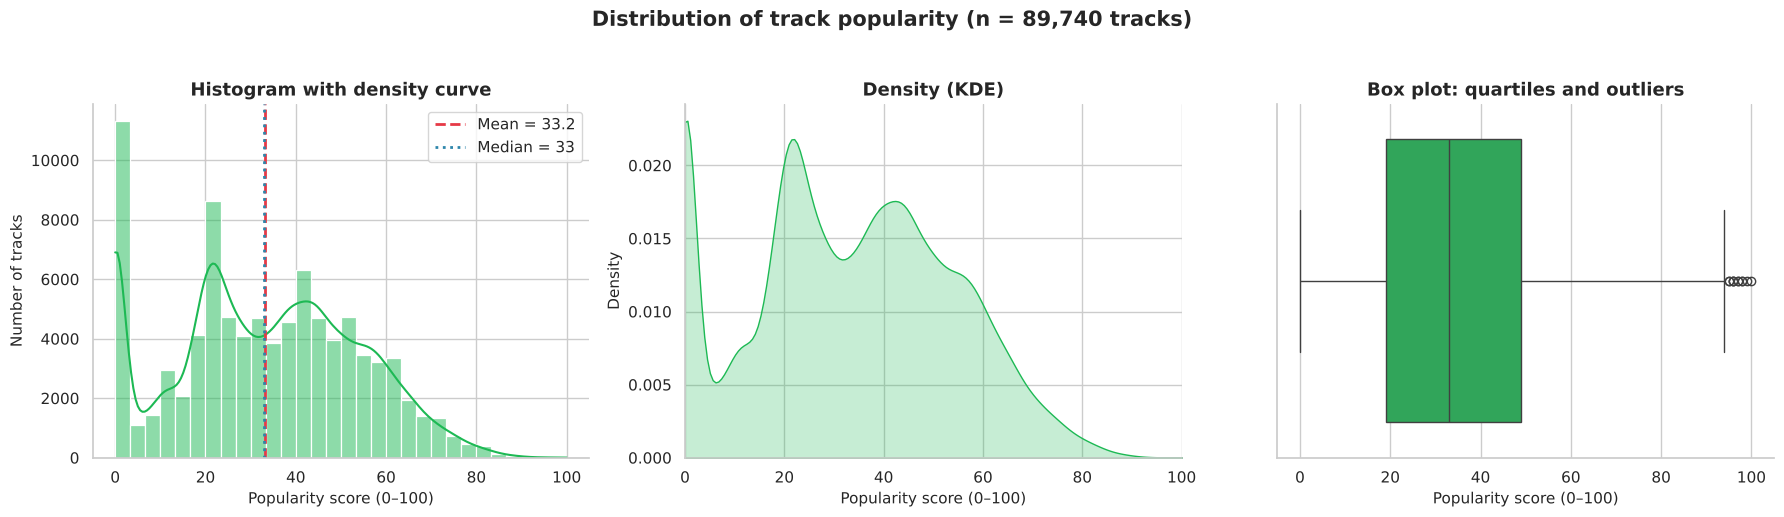

Saved: visuals/01_popularity_distribution.png
count   89,740.000
mean        33.200
std         20.580
min          0.000
25%         19.000
50%         33.000
75%         49.000
max        100.000

Skewness: 0.07
Tracks with popularity >= 50: 23.6%
Tracks with popularity == 0:  9,447 (10.5%)


In [7]:
popularity = df_clean["popularity"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(popularity, bins=30, kde=True, ax=axes[0], color=GREEN)
axes[0].axvline(popularity.mean(), color=RED, ls="--", lw=2, label=f"Mean = {popularity.mean():.1f}")
axes[0].axvline(popularity.median(), color=BLUE, ls=":", lw=2, label=f"Median = {popularity.median():.0f}")
axes[0].set(title="Histogram with density curve", xlabel="Popularity score (0–100)", ylabel="Number of tracks")
axes[0].legend()

sns.kdeplot(popularity, fill=True, ax=axes[1], color=GREEN)
axes[1].set(title="Density (KDE)", xlabel="Popularity score (0–100)", ylabel="Density", xlim=(0, 100))

sns.boxplot(x=popularity, ax=axes[2], color=GREEN)
axes[2].set(title="Box plot: quartiles and outliers", xlabel="Popularity score (0–100)")

fig.suptitle(f"Distribution of track popularity (n = {len(popularity):,} tracks)", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
finish_figure(fig, "01_popularity_distribution.png")

print(popularity.describe().round(2).to_string())
print(f"\nSkewness: {popularity.skew():.2f}")
print(f"Tracks with popularity >= 50: {(popularity >= 50).mean():.1%}")
print(f"Tracks with popularity == 0:  {(popularity == 0).sum():,} ({(popularity == 0).mean():.1%})")

**What the results show**

- Popularity averages **33.2** (median 33, standard deviation 20.6); the middle half of tracks scores between 19 and 49, and 23.6% score 50 or higher.
- The mean and median are almost the same and the skewness is close to 0 (0.07), so the distribution is **not noticeably skewed** in either direction.
- **9,447 tracks (10.5%) have a popularity of exactly 0**, shown as the tall bar at the far left. Apart from that spike the density has two broad humps, around 20 and 40. The dataset does not say what a score of 0 means (the metric is defined by Spotify).
- The box plot marks only scores above roughly 94 as outliers.

### 5.2 Genre sizes after cleaning

**Examines:** how many tracks each of the 20 largest genres has after cleaning (genres with equal counts are ordered alphabetically). This matters because every genre-level average later in the notebook rests on these counts.

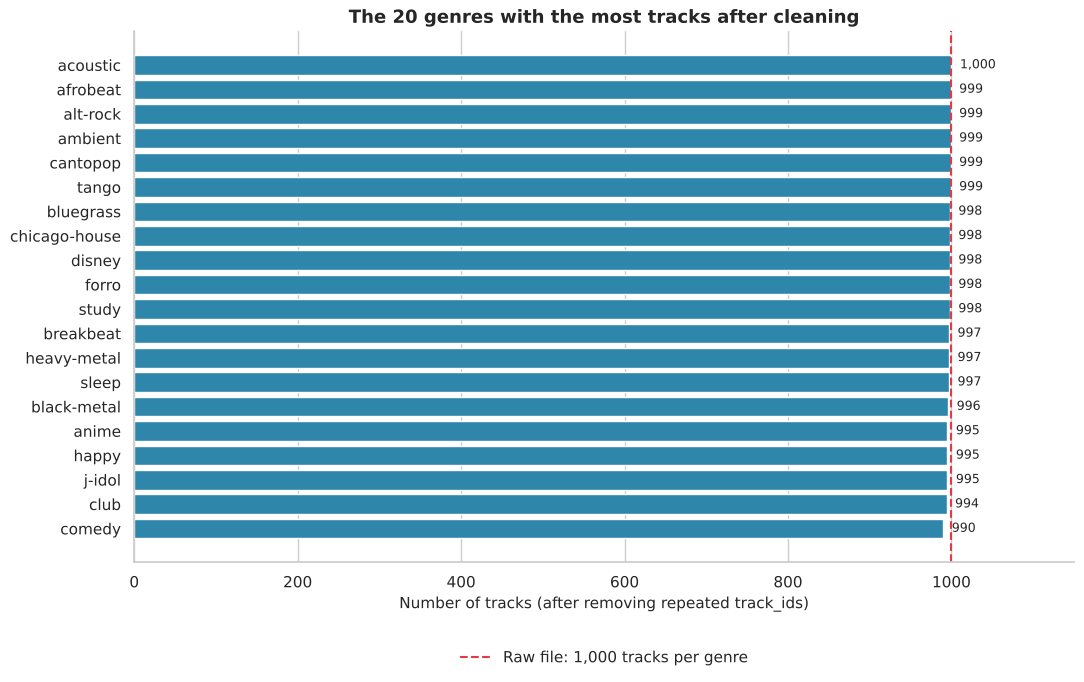

Saved: visuals/02_top_genres_count.png
Smallest genres after cleaning:
track_genre
reggaeton     74
indie        134
house        210
punk         226
metal        232


In [8]:
# Ties in size are broken alphabetically so the selection is the same on every run and pandas version
genres_by_size = genre_summary["n_tracks"].sort_index().sort_values(ascending=False, kind="stable")
top_20_by_count = genres_by_size.head(20)

fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(top_20_by_count.index[::-1], top_20_by_count.values[::-1], color=BLUE)
ax.axvline(1000, color=RED, ls="--", lw=1.5, label="Raw file: 1,000 tracks per genre")
label_bar_ends(ax, [f"{v:,}" for v in top_20_by_count.values[::-1]])
ax.set(title="The 20 genres with the most tracks after cleaning",
       xlabel="Number of tracks (after removing repeated track_ids)", ylabel="")
ax.set_xlim(0, 1150)
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), frameon=False)
plt.tight_layout()
finish_figure(fig, "02_top_genres_count.png")

print("Smallest genres after cleaning:")
print(genre_summary["n_tracks"].sort_values().head(5).to_string())

**What the results show**

- The raw file has exactly 1,000 tracks per genre. After cleaning, genres range from **74 tracks (reggaeton) to 1,000**, with a median of 873; the smallest are reggaeton (74), indie (134), house (210), punk (226) and metal (232).
- The raw file is ordered by genre and the first listing of each track is kept, so a genre's size after cleaning depends on how many of its tracks were already listed under another genre. A genre's size here therefore says nothing about how common that genre is on Spotify.
- Averages for the smaller genres (5.10) rest on fewer tracks, so they are less certain.

### 5.3 Audio feature distributions

**Examines:** the shape of the eight audio features that are scaled 0–1 or measured in BPM (loudness is examined in 5.4 and 5.6). Dashed lines mark each feature's mean.

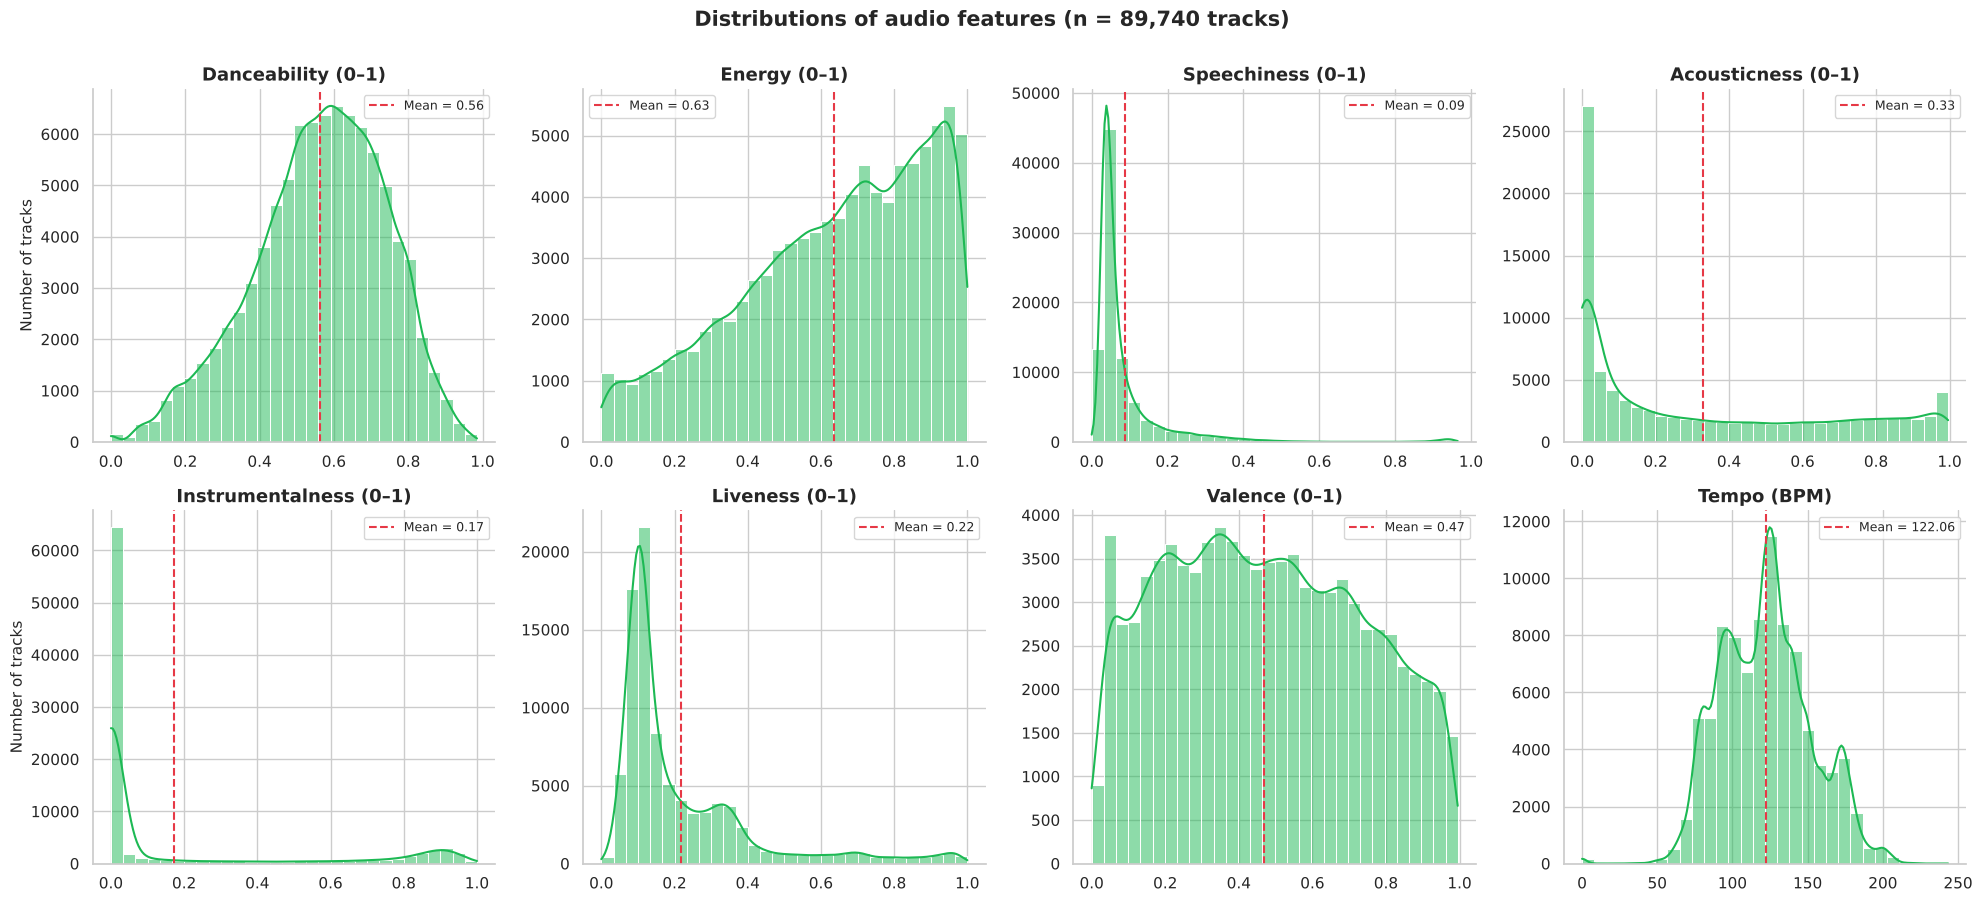

Saved: visuals/03_audio_features_distribution.png


,mean,median,std,min,max,skew
danceability,0.562,0.576,0.177,0.000,0.985,-0.398
energy,0.634,0.676,0.257,0.000,1.000,-0.560
speechiness,0.087,0.049,0.113,0.000,0.965,4.546
acousticness,0.328,0.188,0.338,0.000,0.996,0.656
instrumentalness,0.173,0.000,0.324,0.000,1.000,1.564
liveness,0.217,0.132,0.195,0.000,1.000,2.062
valence,0.469,0.457,0.263,0.000,0.995,0.128
tempo,122.058,122.013,30.118,0.000,243.372,0.183


In [9]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, feature in zip(axes.flatten(), AUDIO_FEATURES):
    sns.histplot(df_clean[feature], bins=30, kde=True, ax=ax, color=GREEN)
    mean_value = df_clean[feature].mean()
    ax.axvline(mean_value, color=RED, ls="--", lw=1.5, label=f"Mean = {mean_value:.2f}")
    ax.set(title=FEATURE_LABELS[feature], xlabel="", ylabel="Number of tracks" if ax in axes[:, 0] else "")
    ax.legend(fontsize=9)
fig.suptitle(f"Distributions of audio features (n = {len(df_clean):,} tracks)", fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout()
finish_figure(fig, "03_audio_features_distribution.png")

audio_summary = df_clean[AUDIO_FEATURES].agg(["mean", "median", "std", "min", "max", "skew"]).T
audio_summary

**What the results show**

- **Roughly bell-shaped or broad:** danceability (mean 0.56, median 0.58, mild tail towards low values), valence (mean 0.47, broad and close to symmetric) and tempo (mean and median about 122 BPM, several peaks, plus a small group at 0 BPM that are placeholder values). Energy leans towards high values (median 0.68, mean 0.63).
- **Concentrated near zero with a long right tail:** speechiness (median 0.05, skewness 4.5), instrumentalness (median 0.00, mean 0.17, skewness 1.6) and liveness (median 0.13, skewness 2.1). For most tracks these features have low values, with a minority of tracks at high values.
- **Acousticness** piles up at low values (median 0.19, mean 0.33) with a small rise near 1.
- Strongly skewed features mean that a small number of extreme tracks can have a large influence on Pearson correlations, which is worth keeping in mind in 5.6.

### 5.4 Popularity vs individual audio features

**Examines:** whether tracks with higher or lower values of a feature tend to have higher or lower popularity. Each panel plots a 5,000-track random sample with a straight-line fit; the **r in each title is the Pearson correlation computed on all cleaned tracks**, not on the sample.

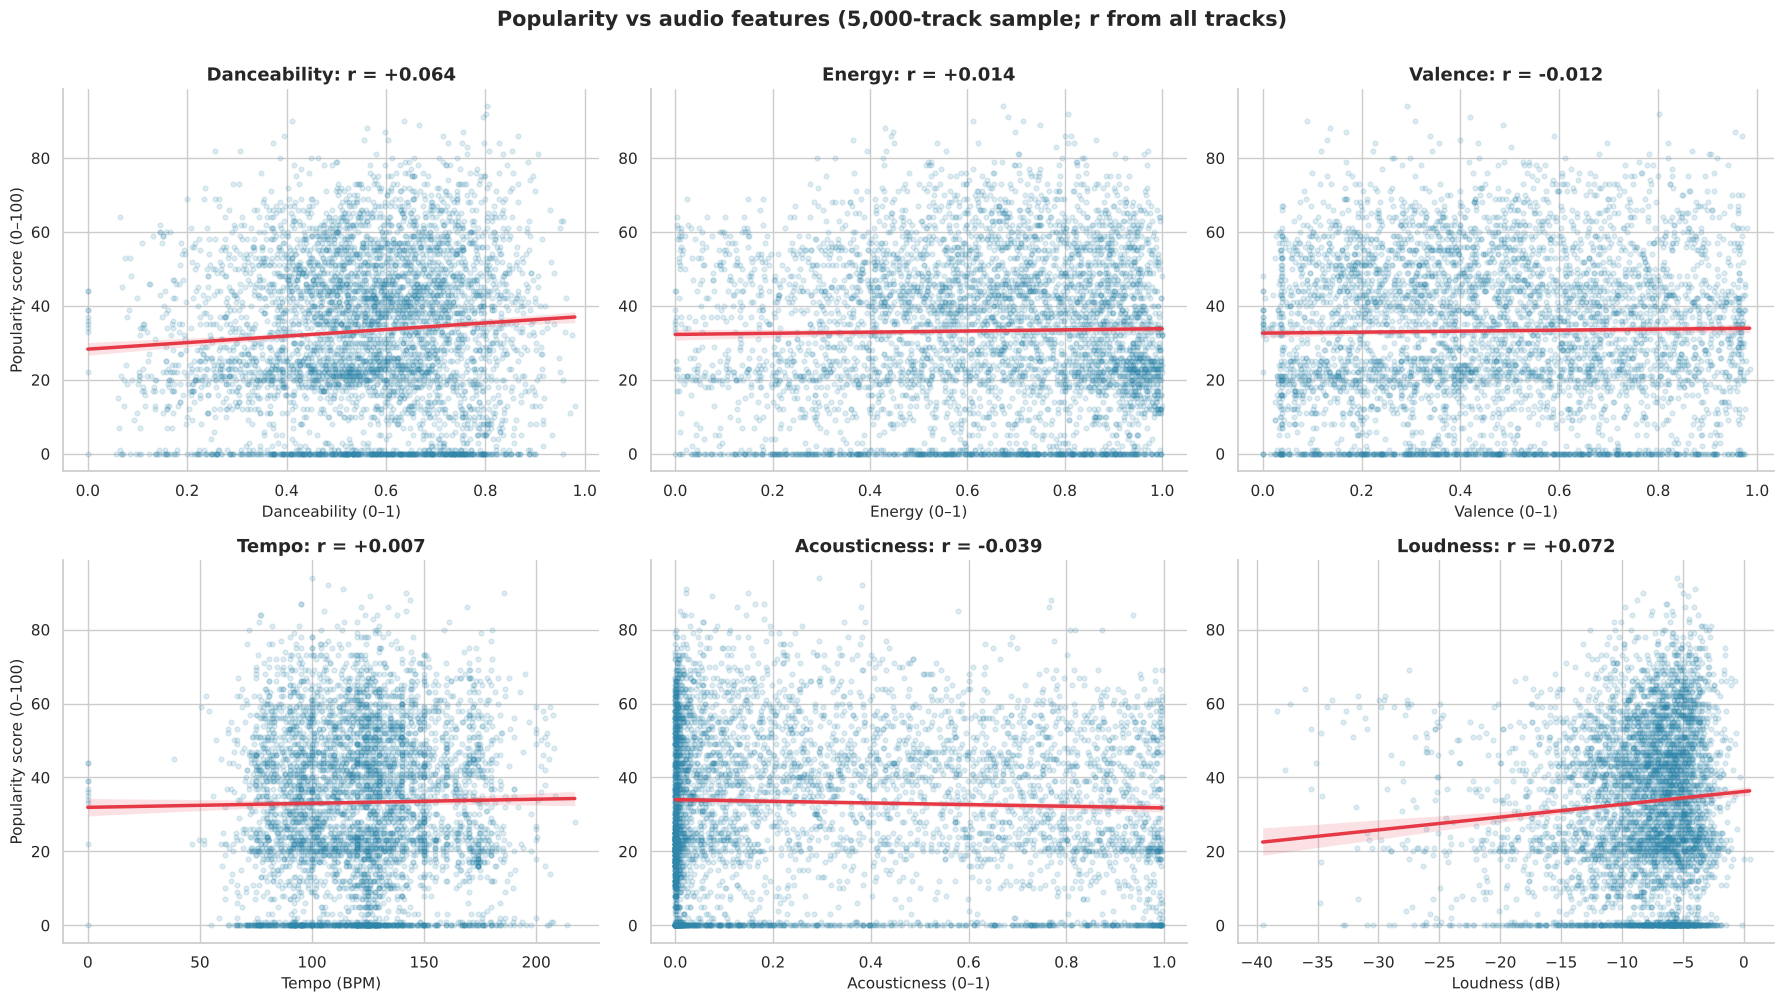

Saved: visuals/04_popularity_vs_audio_features.png


In [10]:
SCATTER_FEATURES = ["danceability", "energy", "valence", "tempo", "acousticness", "loudness"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, feature in zip(axes.flatten(), SCATTER_FEATURES):
    r_full = df_clean[feature].corr(df_clean["popularity"])
    sns.regplot(data=sample_df, x=feature, y="popularity", ax=ax,
                scatter_kws={"alpha": 0.15, "color": BLUE, "s": 12},
                line_kws={"color": RED, "linewidth": 2.5})
    ax.set(title=f"{FEATURE_LABELS[feature].split(' (')[0]}: r = {r_full:+.3f}",
           xlabel=FEATURE_LABELS[feature], ylabel="Popularity score (0–100)" if ax in axes[:, 0] else "")
fig.suptitle("Popularity vs audio features (5,000-track sample; r from all tracks)", fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout()
finish_figure(fig, "04_popularity_vs_audio_features.png")

**What the results show**

- Every fitted line is nearly flat. Correlations with popularity range from **−0.04 to +0.07** for these six features (loudness +0.07, danceability +0.06, acousticness −0.04, energy +0.01, valence −0.01, tempo +0.01), so each feature accounts for well under 1% of the variation in popularity.
- At any value of any feature, tracks span almost the whole popularity range. The horizontal band at 0 in every panel is the group of tracks with a popularity of exactly 0 (see 5.1).
- Knowing one audio feature therefore tells us very little about a track's popularity. This is an association in this dataset, not evidence about cause.

### 5.5 Popularity by genre (distribution)

**Examines:** how popularity is spread *within* genres. The 15 genres with the most cleaned tracks are shown, ordered by median popularity (highest on the left); the number of tracks `n` is printed under each name. These are the largest genres, **not** a ranking of all genres. Violin width shows how many tracks sit at each popularity level and the dashed lines are the quartiles.

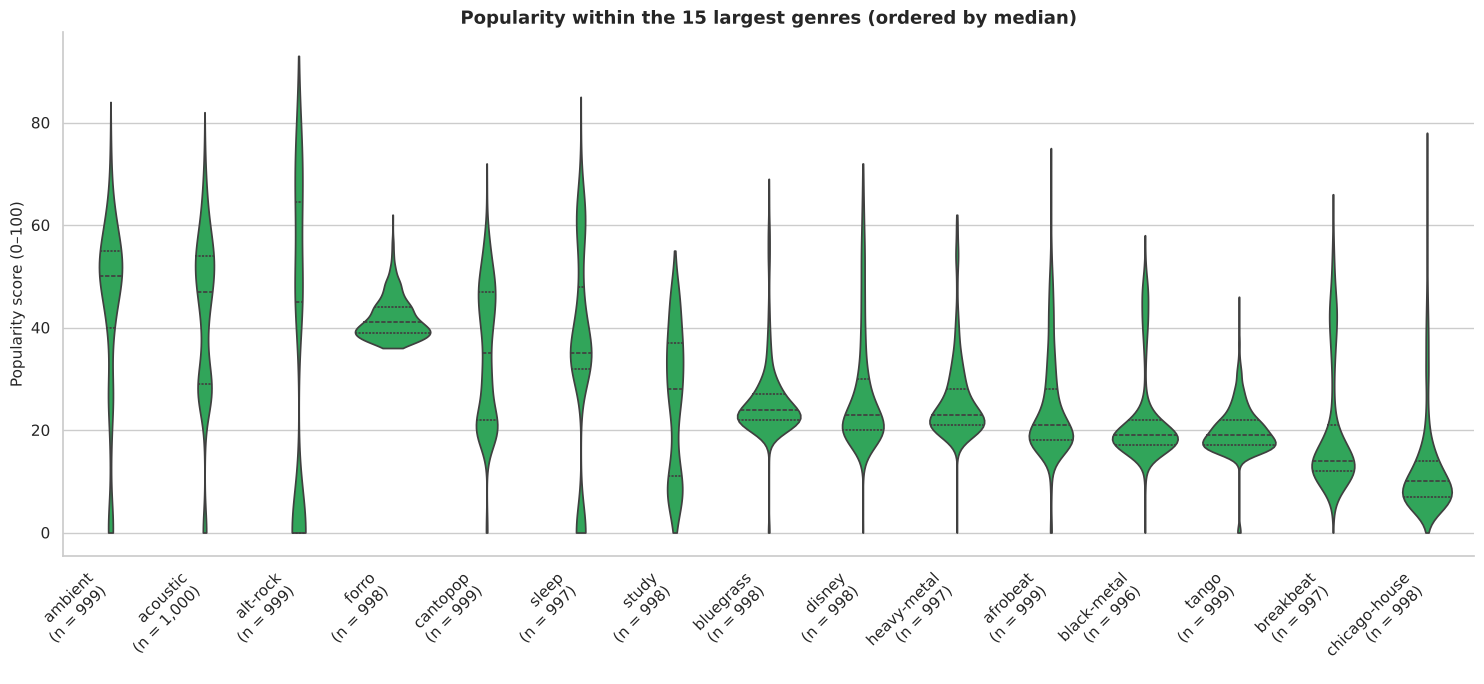

Saved: visuals/05_genre_vs_popularity_violin.png


,n_tracks,mean_popularity,median_popularity
track_genre,,,
ambient,999,44.208,50.000
acoustic,1000,42.483,47.000
alt-rock,999,33.897,45.000
forro,998,41.832,41.000
cantopop,999,34.754,35.000
sleep,997,35.042,35.000
study,998,26.128,28.000
bluegrass,998,25.681,24.000
disney,998,27.488,23.000


In [11]:
top_15_by_count = genres_by_size.head(15).index
df_top_15 = df_clean[df_clean["track_genre"].isin(top_15_by_count)]
violin_order = (genre_summary.loc[top_15_by_count].sort_index()
                .sort_values("median_popularity", ascending=False, kind="stable").index)
violin_tick_labels = [f"{genre}\n(n = {genre_summary.loc[genre, 'n_tracks']:,})" for genre in violin_order]

fig, ax = plt.subplots(figsize=(15, 7))
sns.violinplot(data=df_top_15, x="track_genre", y="popularity", order=violin_order,
               color=GREEN, inner="quartile", cut=0, ax=ax)
ax.set_xticks(range(len(violin_order)))
ax.set_xticklabels(violin_tick_labels, rotation=45, ha="right")
ax.set(title="Popularity within the 15 largest genres (ordered by median)",
       xlabel="", ylabel="Popularity score (0–100)")
plt.tight_layout()
finish_figure(fig, "05_genre_vs_popularity_violin.png")

genre_summary.loc[violin_order]

**What the results show**

- All 15 genres shown have 996–1,000 tracks, yet their **median popularity ranges from 10 (chicago-house) to 50 (ambient)**; acoustic (47) and alt-rock (45) are also high, breakbeat (14) and tango (19) low.
- Spreads differ too: some genres are concentrated in a narrow band, others cover most of the 0–100 scale. A single average therefore hides a lot of variation within a genre.
- These are the largest genres after deduplication, not a random or representative selection of all 113 genres; the extremes across all genres are in 5.10.

### 5.6 Correlation analysis

**Examines:** the pairwise **Pearson correlation** between all numeric columns. Pearson r measures the strength of a *linear association* between two variables (−1 to +1); it says nothing about cause. To put weak values in context, the table also gives **r²**, the share of the variation in popularity that a straight-line relationship with that one feature accounts for.

Rule of thumb used for the labels: |r| < 0.05 negligible, 0.05 to < 0.20 weak, 0.20 to < 0.50 moderate, ≥ 0.50 strong.

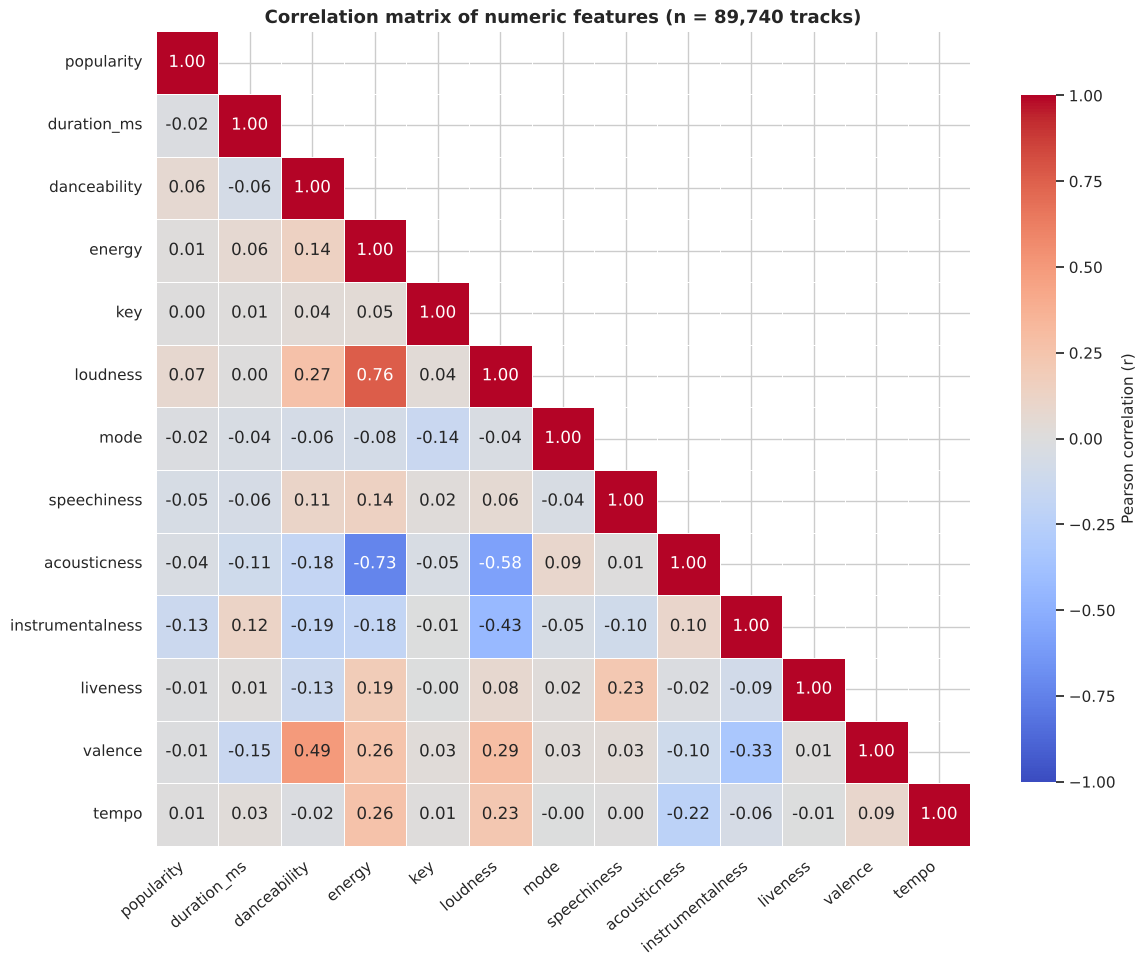

Saved: visuals/06_correlation_heatmap.png


,r,r_squared,strength
instrumentalness,-0.127,1.63%,weak
loudness,+0.072,0.51%,weak
danceability,+0.064,0.41%,weak
speechiness,-0.047,0.22%,negligible
acousticness,-0.039,0.15%,negligible
duration_ms,-0.023,0.05%,negligible
mode,-0.016,0.03%,negligible
liveness,-0.014,0.02%,negligible
energy,+0.014,0.02%,negligible
valence,-0.012,0.01%,negligible


In [12]:
corr_matrix = df_clean[NUMERIC_COLUMNS].corr()

fig, ax = plt.subplots(figsize=(12, 10))
upper_triangle = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, mask=upper_triangle, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax,
            cbar_kws={"label": "Pearson correlation (r)", "shrink": 0.8})
ax.set_title(f"Correlation matrix of numeric features (n = {len(df_clean):,} tracks)")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
finish_figure(fig, "06_correlation_heatmap.png")


def strength_label(r):
    """Plain-language label for the size of a correlation (rule of thumb, not a statistical test)."""
    size = abs(r)
    if size >= 0.5:
        return "strong"
    if size >= 0.2:
        return "moderate"
    if size >= 0.05:
        return "weak"
    return "negligible"


popularity_correlations = (corr_matrix["popularity"].drop("popularity")
                           .sort_values(key=abs, ascending=False).to_frame("r"))
popularity_correlations["r_squared"] = popularity_correlations["r"] ** 2
popularity_correlations["strength"] = popularity_correlations["r"].map(strength_label)
popularity_correlations.style.format({"r": "{:+.3f}", "r_squared": "{:.2%}"})

**What the results show**

- **All correlations with popularity are small.** The largest is instrumentalness at **−0.13** (r² = 1.6%: a straight-line relationship with it accounts for about 1.6% of the variation in popularity), followed by loudness (+0.07) and danceability (+0.06), which are weak. The remaining features have |r| below 0.05 — essentially none. Duration (−0.02), mode (−0.02) and key (0.00) are among them.
- Read as associations: tracks with higher instrumentalness tend to score slightly lower, and louder or more danceable tracks slightly higher. These tendencies are far too small to predict an individual track's popularity, and they do not show that the feature affects popularity.
- **The strong correlations are between features, not with popularity:** loudness ↔ energy (+0.76), acousticness ↔ energy (−0.73) and acousticness ↔ loudness (−0.58). These features overlap in what they capture, so their separate links to popularity should not be treated as independent findings.
- Pearson r only detects straight-line relationships and can be influenced by the skewed features and the spike at popularity 0.

### 5.7 Pairwise relationships between key features

**Examines:** scatter plots of popularity, danceability, energy, valence and loudness against each other (5,000-track sample), with each variable's density on the diagonal.

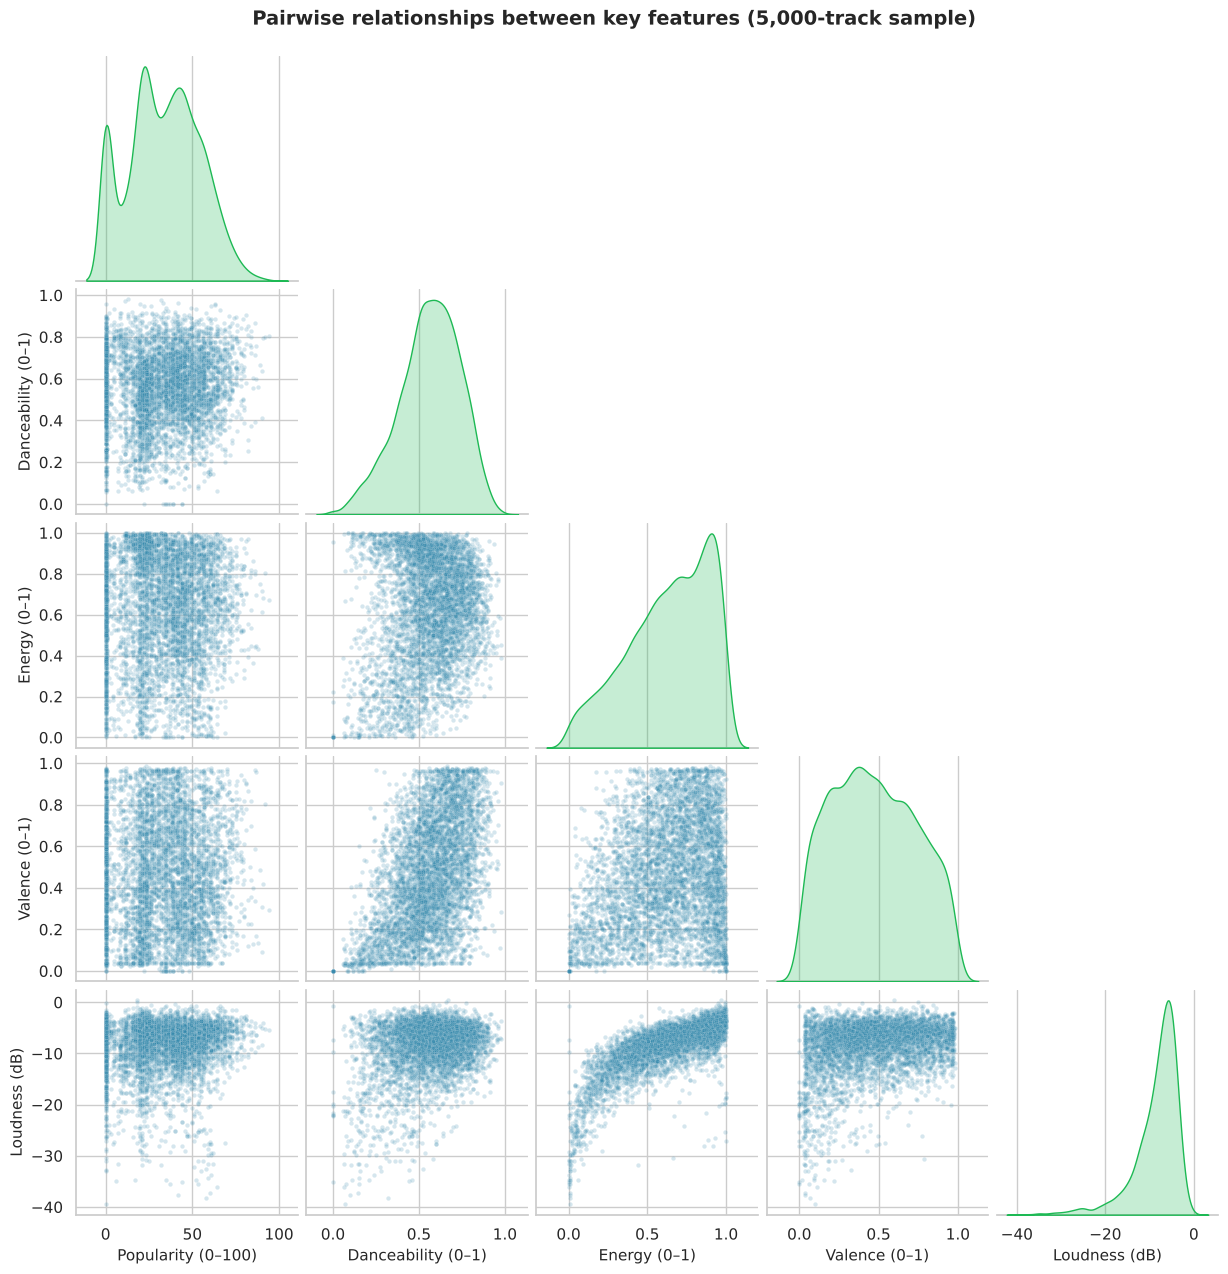

Saved: visuals/07_key_features_pairplot.png


In [13]:
PAIR_COLUMNS = ["popularity", "danceability", "energy", "valence", "loudness"]
pair_labels = {"popularity": "Popularity (0–100)", "danceability": "Danceability (0–1)", "energy": "Energy (0–1)",
               "valence": "Valence (0–1)", "loudness": "Loudness (dB)"}

pair_grid = sns.pairplot(sample_df[PAIR_COLUMNS].rename(columns=pair_labels), diag_kind="kde", corner=True,
                         plot_kws={"alpha": 0.2, "color": BLUE, "s": 10},
                         diag_kws={"color": GREEN})
pair_grid.fig.suptitle("Pairwise relationships between key features (5,000-track sample)",
                       y=1.02, fontsize=14, fontweight="bold")
finish_figure(pair_grid.fig, "07_key_features_pairplot.png")

**What the results show**

- The popularity row and column show no visible pattern against any of the four features, consistent with the small correlations in 5.4 and 5.6.
- The structure that is visible is among the features themselves, in line with the correlations: louder tracks tend to be higher in energy (r = +0.76) and danceability and valence tend to rise together (r = +0.49).

### 5.8 Danceability × energy combinations

**Examines:** whether tracks that are both danceable and energetic differ in popularity from other tracks. Each track is placed in one of four groups using a fixed cut-off of **0.6** for danceability and for energy ("High" = above 0.6). The cut-off is a simple convention, not a data-driven threshold.

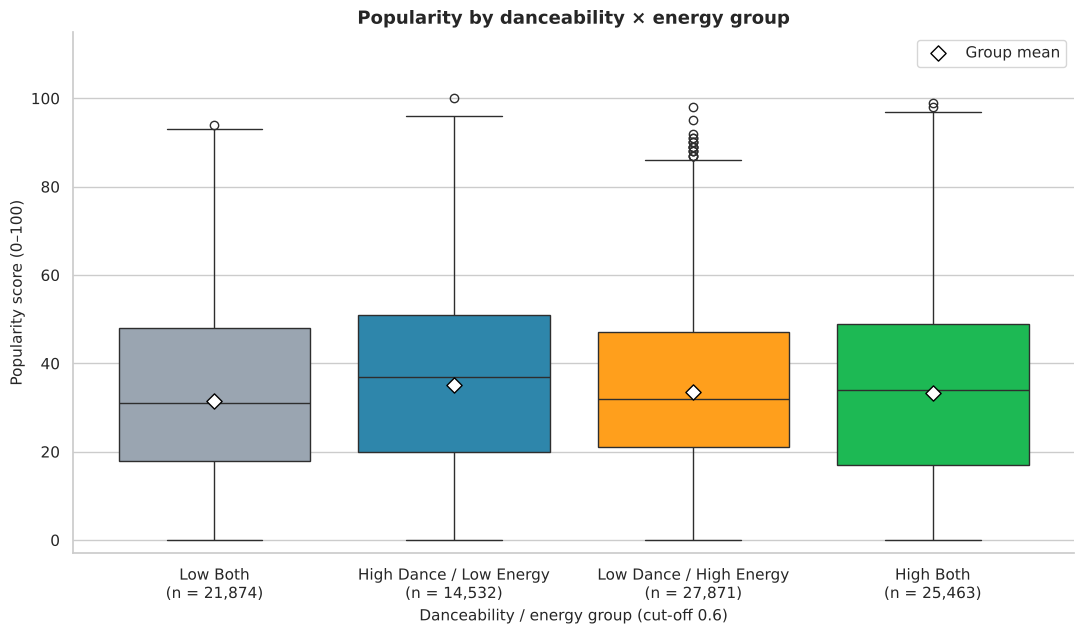

Saved: visuals/08_dance_energy_interaction.png


,n_tracks,mean_popularity,median_popularity,mean_vs_low_both
dance_energy_group,,,,
Low Both,"21,874",31.4,31,+0.0%
High Dance / Low Energy,"14,532",35.1,37,+11.8%
Low Dance / High Energy,"27,871",33.6,32,+7.0%
High Both,"25,463",33.2,34,+5.8%


In [14]:
df_clean["dance_energy_group"] = "Low Both"
df_clean.loc[(df_clean["danceability"] > 0.6) & (df_clean["energy"] > 0.6), "dance_energy_group"] = "High Both"
df_clean.loc[(df_clean["danceability"] > 0.6) & (df_clean["energy"] <= 0.6), "dance_energy_group"] = "High Dance / Low Energy"
df_clean.loc[(df_clean["danceability"] <= 0.6) & (df_clean["energy"] > 0.6), "dance_energy_group"] = "Low Dance / High Energy"

GROUP_ORDER = ["Low Both", "High Dance / Low Energy", "Low Dance / High Energy", "High Both"]
GROUP_COLORS = dict(zip(GROUP_ORDER, ["#9AA5B1", BLUE, ORANGE, GREEN]))

group_summary = (df_clean.groupby("dance_energy_group")["popularity"]
                 .agg(n_tracks="count", mean_popularity="mean", median_popularity="median")
                 .loc[GROUP_ORDER])
group_summary["mean_vs_low_both"] = group_summary["mean_popularity"] / group_summary.loc["Low Both", "mean_popularity"] - 1

fig, ax = plt.subplots(figsize=(11, 6.5))
sns.boxplot(data=df_clean, x="dance_energy_group", y="popularity", order=GROUP_ORDER, color="#4D4D4D", ax=ax)
color_boxes(ax, [GROUP_COLORS[group] for group in GROUP_ORDER])
ax.scatter(range(len(GROUP_ORDER)), group_summary["mean_popularity"], marker="D", color="white",
           edgecolor="black", zorder=5, s=60, label="Group mean")
ax.set_xticks(range(len(GROUP_ORDER)))
ax.set_xticklabels([f"{g}\n(n = {group_summary.loc[g, 'n_tracks']:,})" for g in GROUP_ORDER])
ax.set(title="Popularity by danceability × energy group", xlabel="Danceability / energy group (cut-off 0.6)",
       ylabel="Popularity score (0–100)", ylim=(-3, 115))
ax.legend(loc="upper right")
plt.tight_layout()
finish_figure(fig, "08_dance_energy_interaction.png")

group_summary.style.format({"n_tracks": "{:,}", "mean_popularity": "{:.1f}", "median_popularity": "{:.0f}",
                            "mean_vs_low_both": "{:+.1%}"})

**What the results show**

- Mean popularity is 31.4 for "Low Both" (n = 21,874), 33.6 for "Low Dance / High Energy" (n = 27,871), 33.2 for "High Both" (n = 25,463) and **35.1 for "High Dance / Low Energy"** (n = 14,532), the highest. Relative to "Low Both" that is +7.0%, +5.8% and +11.8%.
- The largest gap between group means is 3.7 points on a 0–100 scale, small next to the overall standard deviation of 20.6, and the boxes overlap heavily. Tracks that are both danceable and energetic are **not** the most popular group here.
- The 0.6 cut-off is arbitrary and no significance test was run, so this shows only that the group averages differ slightly.

### 5.9 Explicit vs clean tracks

**Examines:** the popularity of tracks flagged `explicit` compared with the rest. The comparison is descriptive: it reports group averages and does not control for genre or anything else.

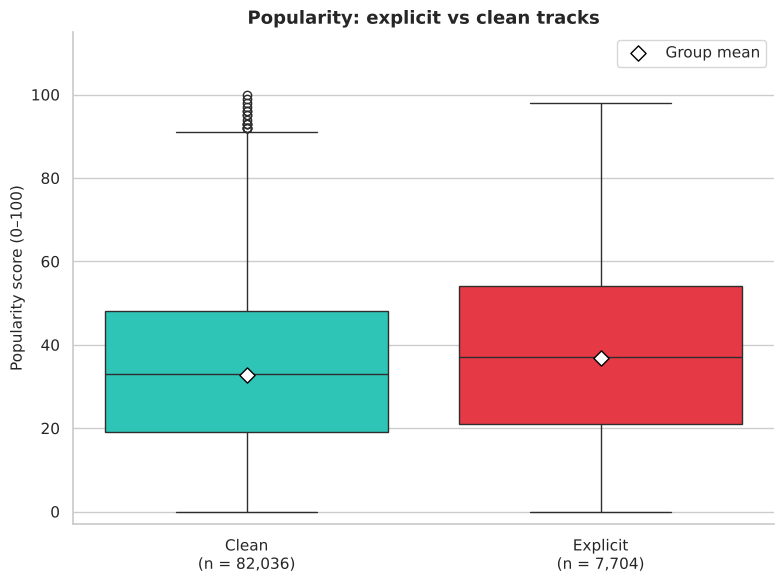

Saved: visuals/09_explicit_vs_popularity.png
Explicit share of tracks: 8.6% (7,704 of 89,740)
Mean popularity — explicit: 36.9, clean: 32.9
Median popularity — explicit: 37, clean: 33
Difference in means (explicit − clean): +4.0 points (0.20 standard deviations of popularity)


In [15]:
explicit_tracks = df_clean[df_clean["explicit"]]
clean_tracks = df_clean[~df_clean["explicit"]]
mean_difference = explicit_tracks["popularity"].mean() - clean_tracks["popularity"].mean()

fig, ax = plt.subplots(figsize=(8, 6))
sns.boxplot(data=df_clean, x="explicit", y="popularity", order=[False, True], color="#4D4D4D", ax=ax)
color_boxes(ax, [TEAL, RED])
ax.scatter([0, 1], [clean_tracks["popularity"].mean(), explicit_tracks["popularity"].mean()], marker="D",
           color="white", edgecolor="black", zorder=5, s=60, label="Group mean")
ax.set_xticks([0, 1])
ax.set_xticklabels([f"Clean\n(n = {len(clean_tracks):,})", f"Explicit\n(n = {len(explicit_tracks):,})"])
ax.set(title="Popularity: explicit vs clean tracks", xlabel="", ylabel="Popularity score (0–100)", ylim=(-3, 115))
ax.legend(loc="upper right")
plt.tight_layout()
finish_figure(fig, "09_explicit_vs_popularity.png")

print(f"Explicit share of tracks: {df_clean['explicit'].mean():.1%} ({len(explicit_tracks):,} of {len(df_clean):,})")
print(f"Mean popularity — explicit: {explicit_tracks['popularity'].mean():.1f}, clean: {clean_tracks['popularity'].mean():.1f}")
print(f"Median popularity — explicit: {explicit_tracks['popularity'].median():.0f}, clean: {clean_tracks['popularity'].median():.0f}")
print(f"Difference in means (explicit − clean): {mean_difference:+.1f} points "
      f"({mean_difference / df_clean['popularity'].std():.2f} standard deviations of popularity)")

**What the results show**

- 8.6% of tracks (7,704) are flagged explicit. Their mean popularity is **36.9 versus 32.9** for clean tracks (medians 37 and 33), a difference of **+4.0 points, about 0.2 standard deviations** of popularity.
- The difference is small compared with the spread inside each group (the boxes overlap heavily), so an explicit flag says little about an individual track.
- This is an association only. The comparison does not account for genre, and explicit tracks may be concentrated in particular genres, so the difference cannot be attributed to explicitness itself.

### 5.10 Genres with the highest average popularity

**How the averages are calculated:** for each genre, the **simple mean of `popularity` over its cleaned tracks**. Every track counts once and no minimum genre size is applied, so genres with fewer tracks (printed as `n`) have less certain averages. The chart shows the 15 genres with the highest means; the table below it adds the 5 lowest.

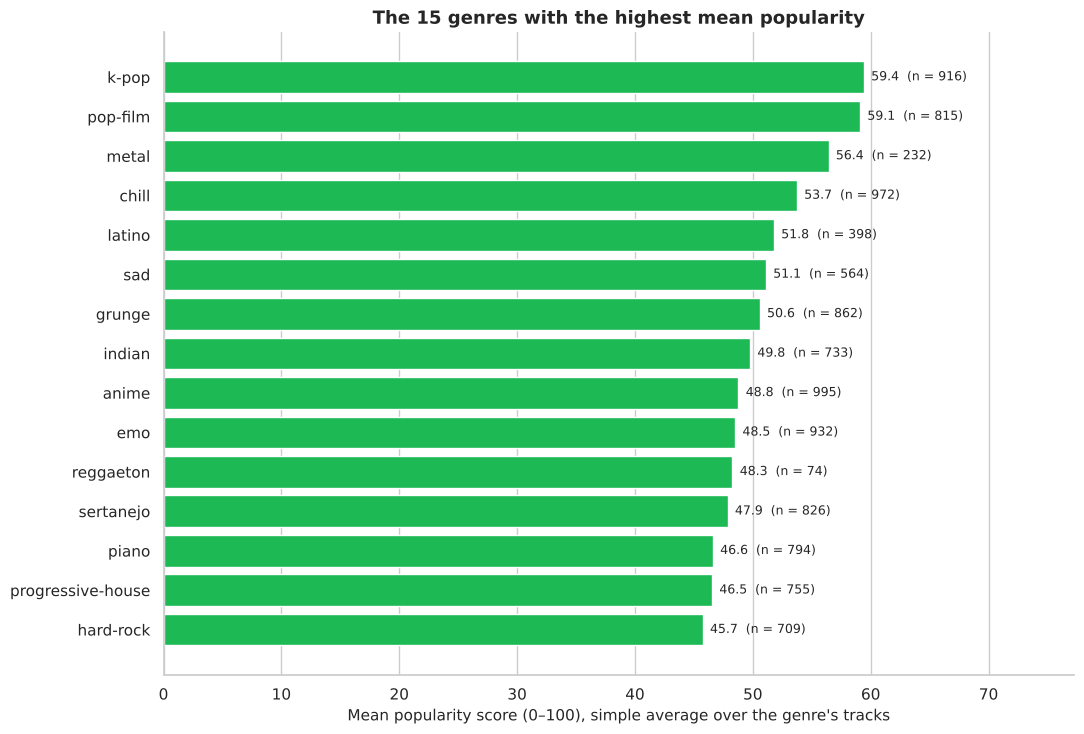

Saved: visuals/10_top_genres_by_avg_popularity.png
Top 10 genres by mean popularity:
             n_tracks  mean_popularity  median_popularity
track_genre                                              
k-pop             916           59.424             61.000
pop-film          815           59.097             60.000
metal             232           56.422             63.000
chill             972           53.739             57.000
latino            398           51.789             46.000
sad               564           51.110             52.000
grunge            862           50.587             54.000
indian            733           49.765             49.000
anime             995           48.777             50.000
emo               932           48.500             50.000

5 lowest genres by mean popularity:
                n_tracks  mean_popularity  median_popularity
track_genre                                                 
detroit-techno       956           11.131              8.000

In [16]:
genres_by_mean = genre_summary.sort_values("mean_popularity", ascending=False)
top_15_by_mean = genres_by_mean.head(15)

fig, ax = plt.subplots(figsize=(11, 7.5))
ax.barh(top_15_by_mean.index[::-1], top_15_by_mean["mean_popularity"][::-1], color=GREEN)
label_bar_ends(ax, [f"{m:.1f}  (n = {n:,})" for m, n in
                    zip(top_15_by_mean["mean_popularity"][::-1], top_15_by_mean["n_tracks"][::-1])])
ax.set_xlim(0, top_15_by_mean["mean_popularity"].max() * 1.3)
ax.grid(axis="y", visible=False)
ax.set(title="The 15 genres with the highest mean popularity",
       xlabel="Mean popularity score (0–100), simple average over the genre's tracks", ylabel="")
plt.tight_layout()
finish_figure(fig, "10_top_genres_by_avg_popularity.png")

print("Top 10 genres by mean popularity:")
print(genres_by_mean.head(10)[["n_tracks", "mean_popularity", "median_popularity"]].to_string())
print("\n5 lowest genres by mean popularity:")
print(genres_by_mean.tail(5)[["n_tracks", "mean_popularity", "median_popularity"]].to_string())

**What the results show**

- Highest means: **k-pop 59.4** (n = 916), **pop-film 59.1** (n = 815), metal 56.4 (n = 232), chill 53.7 (n = 972) and latino 51.8 (n = 398). Lowest: **iranian 2.2** (n = 988), romance 3.5 (n = 904), jazz 9.8 (n = 524), latin 9.9 (n = 759) and detroit-techno 11.1 (n = 956).
- The gap between the highest and lowest genre mean is about **57 points** on a 0–100 scale, much larger than any difference seen for audio features, the danceability × energy groups or explicit tracks.
- In latin, jazz, romance and iranian the median popularity is 0, i.e. at least half of their tracks score exactly 0, which pulls their averages down.
- Means for genres with fewer tracks (metal 232, latino 398, and reggaeton, which appears at n = 74) rest on less data than those for genres with about 1,000 tracks. A genre mean describes the genre's tracks in this dataset; it is not a prediction for any single track and does not explain why the genre differs.

### 5.11 Interactive dashboard

Collects six of the views above into one interactive Plotly page (hover for values). The cell reuses the genre table and correlation matrix computed above; its panels and output file (`dashboard/spotify_dashboard.html`) are the same as in the previous version of the notebook.

In [17]:
KEY_NAMES = {0: "C", 1: "C#", 2: "D", 3: "D#", 4: "E", 5: "F", 6: "F#", 7: "G", 8: "G#", 9: "A", 10: "A#", 11: "B"}
df_clean["key_name"] = df_clean["key"].map(KEY_NAMES)

fig_dash = make_subplots(
    rows=3, cols=2,
    subplot_titles=("Top 10 Genres by Average Popularity", "Popularity vs Energy (1,000-track sample)",
                    "Audio Feature Correlations", "Popularity Distribution",
                    "Explicit Content Breakdown", "Musical Key Distribution"),
    specs=[[{"type": "bar"}, {"type": "scatter"}],
           [{"type": "heatmap"}, {"type": "histogram"}],
           [{"type": "pie"}, {"type": "bar"}]],
)

top_10_by_mean = genres_by_mean.head(10)
fig_dash.add_trace(go.Bar(x=top_10_by_mean.index, y=top_10_by_mean["mean_popularity"],
                          marker_color=GREEN, name="Avg popularity"), row=1, col=1)

dashboard_sample = df_clean.sample(1000, random_state=RANDOM_SEED)
fig_dash.add_trace(go.Scatter(x=dashboard_sample["energy"], y=dashboard_sample["popularity"], mode="markers",
                              marker=dict(color="#1ED760", opacity=0.5), name="Tracks"), row=1, col=2)

fig_dash.add_trace(go.Heatmap(z=corr_matrix.values, x=corr_matrix.columns, y=corr_matrix.index,
                              colorscale="Viridis", name="Correlation"), row=2, col=1)
fig_dash.add_trace(go.Histogram(x=df_clean["popularity"], nbinsx=30, marker_color=BLUE, name="Tracks"), row=2, col=2)

explicit_counts = df_clean["explicit"].value_counts()
fig_dash.add_trace(go.Pie(labels=["Clean", "Explicit"], values=explicit_counts.values,
                          marker_colors=[TEAL, "#E71D36"], name="Explicit ratio"), row=3, col=1)

key_counts = df_clean["key_name"].value_counts().reindex(list(KEY_NAMES.values()))
fig_dash.add_trace(go.Bar(x=key_counts.index, y=key_counts.values, marker_color=ORANGE, name="Key count"), row=3, col=2)

fig_dash.update_layout(title_text="<b>Spotify Music EDA — Interactive Dashboard</b>",
                       template="plotly_dark", height=1200, showlegend=False)

if SAVE_OUTPUTS:
    dashboard_path = DASHBOARD_DIR / "spotify_dashboard.html"
    fig_dash.write_html(dashboard_path)
    print(f"Saved: {dashboard_path.relative_to(ROOT).as_posix()}")

Saved: dashboard/spotify_dashboard.html


## 6. Findings

Key numbers collected from the analysis above (all computed from the cleaned data, no new calculations). The loudness ↔ energy line is a corrected version of the previous notebook's summary, which printed loudness vs *popularity* under that label.

In [18]:
strongest_feature = popularity_correlations["r"].abs().idxmax()
strongest_positive = popularity_correlations["r"].idxmax()

findings = pd.DataFrame([
    ("Tracks analysed (after cleaning)", f"{len(df_clean):,}  (raw file: {len(df_raw):,})"),
    ("Popularity: mean / median / std. dev.", f"{popularity.mean():.1f} / {popularity.median():.0f} / {popularity.std():.1f}"),
    ("Largest |r| with popularity", f"{strongest_feature}  (r = {popularity_correlations.loc[strongest_feature, 'r']:+.3f}, "
                                   f"r² = {popularity_correlations.loc[strongest_feature, 'r_squared']:.1%})"),
    ("Largest positive r with popularity", f"{strongest_positive}  (r = {popularity_correlations.loc[strongest_positive, 'r']:+.3f})"),
    ("Loudness ↔ energy", f"r = {corr_matrix.loc['loudness', 'energy']:+.2f}"),
    ("Acousticness ↔ energy", f"r = {corr_matrix.loc['acousticness', 'energy']:+.2f}"),
    ("Acousticness ↔ loudness", f"r = {corr_matrix.loc['acousticness', 'loudness']:+.2f}"),
    ("Danceability ↔ valence", f"r = {corr_matrix.loc['danceability', 'valence']:+.2f}"),
    ("Energy ↔ valence", f"r = {corr_matrix.loc['energy', 'valence']:+.2f}"),
    ("Danceability × energy groups: range of mean popularity",
     f"{group_summary['mean_popularity'].min():.1f} to {group_summary['mean_popularity'].max():.1f}"),
    ("Explicit tracks: share / mean difference vs clean",
     f"{df_clean['explicit'].mean():.1%} / {mean_difference:+.1f} points"),
    ("Highest mean popularity by genre", f"{genres_by_mean.index[0]}  ({genres_by_mean['mean_popularity'].iloc[0]:.1f}, "
                                          f"n = {genres_by_mean['n_tracks'].iloc[0]:,})"),
    ("Lowest mean popularity by genre", f"{genres_by_mean.index[-1]}  ({genres_by_mean['mean_popularity'].iloc[-1]:.1f}, "
                                         f"n = {genres_by_mean['n_tracks'].iloc[-1]:,})"),
], columns=["Finding", "Value"])
findings.style.hide(axis="index")

Finding,Value
Tracks analysed (after cleaning),"89,740 (raw file: 114,000)"
Popularity: mean / median / std. dev.,33.2 / 33 / 20.6
Largest |r| with popularity,"instrumentalness (r = -0.127, r² = 1.6%)"
Largest positive r with popularity,loudness (r = +0.072)
Loudness ↔ energy,r = +0.76
Acousticness ↔ energy,r = -0.73
Acousticness ↔ loudness,r = -0.58
Danceability ↔ valence,r = +0.49
Energy ↔ valence,r = +0.26
Danceability × energy groups: range of mean popularity,31.4 to 35.1


**Reading the table**

- Audio features are weakly associated with popularity (largest |r| = 0.13, r² = 1.6%); the strong relationships are between features.
- Differences between genres are far larger than differences associated with any single audio feature, the danceability × energy groups or explicit content.
- The explicit difference (+4.0 points) and the group differences (under 4 points) are small compared with a standard deviation of 20.6.
- **Two corrections to the previous summary cell:** (1) it printed the loudness ↔ popularity correlation (+0.072) under the label "Loudness ↔ Energy"; the correct value is +0.76. (2) It labelled instrumentalness (r = −0.127) as "moderate" because its cut-off for "moderate" was 0.1. With the rule of thumb in 5.6 (moderate starts at 0.2) it is "weak", which better matches r² = 1.6%. The correlation values themselves are unchanged.

## 7. Limitations

- **Popularity is a Spotify-defined metric.** The dataset does not explain how the score is calculated or when it was measured, so it is best read as a relative ranking at one point in time, not a direct measure of listening.
- **Audio features alone have weak associations with popularity.** No single feature has |r| above about 0.13 (r² under 2%), so these features cannot explain why a track is popular. Pearson correlation also only captures straight-line relationships; a non-linear pattern could be missed.
- **There is no release-date field.** Trends over time, track age and seasonality cannot be studied.
- **Associations, not causes.** Nothing here shows that changing a feature or adding an explicit tag would change popularity. Differences between groups may reflect other factors, such as the genres explicit tracks belong to; this notebook does not control for them.
- **The sample is built by genre, not drawn from the whole catalogue.** The raw file has exactly 1,000 rows for each of 114 genres, so genre comparisons are meaningful but overall shares (for example the explicit share) do not describe Spotify as a whole.
- **Deduplication shapes the genre data.** Tracks listed under several genres were kept once, under the first listing in the file. This leaves genres with 74 to 1,000 tracks and removes one genre entirely (see section 4), so genre averages — especially for small genres — are less certain.
- **Plots use a 5,000-track sample** for readability; all statistics are computed on the full cleaned data.

### Consistency notes for the repository

Differences found between this notebook's computed results and other files in the repository. They were **not** changed here, because the task was limited to the notebook.

- README and `reports/` describe **113 genres with ~1,000 tracks each in the raw data**. The raw file has 114 genres; 113 remain after cleaning, with 74 to 1,000 tracks each (not "~794 each").
- The cleaning report says 3 rows were dropped for missing values. The 3 missing cells are all in **1 row**.
- `reports/eda_report.md` and the popularity chart in `build_eda_assets.py` call popularity "right-skewed". Here the skewness is close to 0 and the mean (33.2) is almost equal to the median (33).
- The script's genre-count chart is annotated "Balanced". After deduplication genre sizes are not balanced.
- `reports/eda_report.md` names acousticness (r = −0.04) as the strongest negative feature, while instrumentalness has the largest |r| (−0.13), as the same report also states.
- README places loudness's and energy's relationship with acousticness at r = −0.73; that is energy's value. Loudness ↔ acousticness is −0.58.
- The cleaning report states all audio features are in valid ranges, yet the raw file has 157 rows with `tempo` = 0 and 163 with `time_signature` = 0, which are not real measurements.
- Several summary statistics in the README and `reports/eda_report.md` differ from the values computed in 5.3 on the cleaned data: instrumentalness mean 0.002 (computed 0.173), loudness mean −8.2 dB (−8.5), liveness mean 0.19 (0.22), valence mean 0.45 (0.47), acousticness mean 0.31 (0.33). Both files also call danceability right-skewed, but its skewness is −0.40 (mean 0.56 below median 0.58).
- `requirements.txt` allows seaborn ≥ 0.12, but `build_eda_assets.py` passes `legend=False` to categorical plots. Seaborn 0.12.2 rejects that argument for `boxplot`, so the script may fail there; it was not run on 0.12. This notebook avoids the argument and ran on seaborn 0.12.2 and 0.13.2.

## 8. Conclusion

In this dataset, **audio features are only weakly associated with popularity**: the largest correlation is instrumentalness (r = −0.13), loudness is the largest positive one (r = +0.07), and duration, key and mode are close to zero. The strong correlations are *between* features — loudness and energy (r = +0.76), acousticness and energy (r = −0.73) — which describe production style rather than popularity.

**Genre shows the largest differences:** mean popularity runs from about 59 (K-pop, pop-film) down to about 2 (iranian), a range of roughly 57 points, whereas danceability × energy groups differ by under 4 points and explicit tracks by about 4 points. These genre differences are descriptive, and averages for small genres rest on fewer tracks. Explicit tracks average slightly higher popularity (+4 points, about 0.2 standard deviations), a small difference that this notebook does not separate from genre.

These results describe associations in a genre-balanced, deduplicated snapshot of Spotify tracks with a Spotify-defined popularity score and no release dates. They do not show what causes a track to become popular.